# Preprocesamiento: correcciones geométricas y radiométricas

Una imagen recién captada por un sensor no es un mapa ni una medida directa de la superficie. Sus píxeles están desplazados respecto a su posición real por la geometría de la adquisición y por el relieve, y sus valores, los niveles digitales (ND), mezclan la reflectancia de la superficie con el efecto de la atmósfera, la iluminación y la calibración del sensor. El preprocesamiento corrige estas distorsiones para que la imagen se pueda superponer a otra información geográfica y para que sus valores sean comparables entre fechas y sensores {cite}`chuvieco2008,richards2013`.

## Niveles de procesamiento

Las agencias distribuyen las imágenes con distintos niveles de procesamiento. El nivel 0 son los datos crudos del sensor. El nivel 1 tiene correcciones radiométricas de calibración y geométricas de sistema; en Landsat (L1TP) y Sentinel-2 (L1C) además está ortorrectificado con un modelo de elevación, y sus valores son radiancia o reflectancia en el tope de la atmósfera (TOA). El nivel 2 está corregido atmosféricamente y sus valores son reflectancia de superficie, o de fondo de la atmósfera (BOA): es el producto Landsat Collection 2 Level-2 y Sentinel-2 L2A, el que conviene usar en casi todos los análisis. Los niveles superiores son productos derivados, como índices, temperaturas de superficie o coberturas.

## Correcciones geométricas

Las deformaciones geométricas de una imagen tienen causas sistemáticas, que se corrigen con modelos de la plataforma y del sensor (la rotación de la Tierra durante la adquisición, la curvatura terrestre, la variación de la escala a lo largo del barrido, la velocidad y la altitud de la plataforma), y causas no sistemáticas, como las variaciones de actitud (alabeo, cabeceo y guiñada) o el relieve. Las primeras se corrigen con la información orbital; las segundas exigen puntos de control en el terreno (GCP), puntos reconocibles en la imagen con coordenadas conocidas en el mapa.

Con los puntos de control se ajusta una transformación entre las coordenadas de la imagen (columna, fila) y las del mapa (este, norte). La más simple es la afín, o polinomio de primer grado, que admite traslación, rotación, escala y sesgo:

$$E = a_0 + a_1\,c + a_2\,f, \qquad N = b_0 + b_1\,c + b_2\,f.$$

Con más de tres puntos el sistema se resuelve por mínimos cuadrados, y la calidad del ajuste se mide con el error medio cuadrático (RMSE) de los residuos, que debe ser menor que medio píxel. La celda siguiente hace el ajuste con puntos de control simulados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)

# transformación verdadera: píxel de 30 m, rotación de 8°, origen en (430000, 690000)
ang = np.radians(8)
A_real = np.array([[430000, 30 * np.cos(ang), 30 * np.sin(ang)],
                   [690000, -30 * np.sin(ang), -30 * np.cos(ang)]])
cf = rng.uniform(0, 1000, (12, 2))                        # (columna, fila) de 12 GCP
M = np.column_stack([np.ones(12), cf])
EN = M @ A_real.T + rng.normal(0, 8, (12, 2))              # coordenadas de mapa con error de 8 m
coef, *_ = np.linalg.lstsq(M, EN, rcond=None)
res = EN - M @ coef
rmse = np.sqrt((res**2).sum(axis=1).mean())
print('Coeficientes ajustados (E y N):'); print(np.round(coef.T, 3))
print(f'RMSE = {rmse:.1f} m = {rmse/30:.2f} píxeles')
for i in np.argsort(-np.hypot(*res.T))[:3]:
    print(f'  GCP {i:2d}: residuo {np.hypot(*res[i]):5.1f} m')

Coeficientes ajustados (E y N):
[[ 4.29993673e+05  2.97130000e+01  4.18400000e+00]
 [ 6.90001743e+05 -4.17600000e+00 -2.97080000e+01]]
RMSE = 7.3 m = 0.24 píxeles
  GCP  3: residuo  13.4 m
  GCP  8: residuo   9.4 m
  GCP  6: residuo   9.0 m


## Ortorrectificación

La transformación afín no corrige el desplazamiento del relieve, que depende de la altura de cada punto (capítulo {doc}`07_Fotogrametria`). La ortorrectificación usa un modelo digital de elevación y un modelo riguroso del sensor, o un modelo de coeficientes polinomiales racionales (RPC) entregado con la imagen, para llevar cada píxel a su posición ortogonal. En imágenes de satélite con visión vertical el desplazamiento es pequeño, pero en imágenes apuntadas, como las de muy alta resolución tomadas con ángulos de 20 o 30°, puede llegar a cientos de metros en zonas montañosas como los Andes. La celda siguiente estima ese desplazamiento.

In [2]:
for ang_vista in [0, 5, 15, 30]:
    for h in [500, 2000]:
        print(f'ángulo de visión {ang_vista:2d}°, desnivel {h:4d} m -> desplazamiento horizontal {h*np.tan(np.radians(ang_vista)):6.0f} m')

ángulo de visión  0°, desnivel  500 m -> desplazamiento horizontal      0 m
ángulo de visión  0°, desnivel 2000 m -> desplazamiento horizontal      0 m
ángulo de visión  5°, desnivel  500 m -> desplazamiento horizontal     44 m
ángulo de visión  5°, desnivel 2000 m -> desplazamiento horizontal    175 m
ángulo de visión 15°, desnivel  500 m -> desplazamiento horizontal    134 m
ángulo de visión 15°, desnivel 2000 m -> desplazamiento horizontal    536 m
ángulo de visión 30°, desnivel  500 m -> desplazamiento horizontal    289 m
ángulo de visión 30°, desnivel 2000 m -> desplazamiento horizontal   1155 m


## Remuestreo

Una vez definida la transformación, se crea la imagen corregida en una malla regular y, para cada píxel nuevo, se busca su posición en la imagen original. Como esa posición casi nunca coincide con el centro de un píxel, hay que interpolar. El vecino más cercano toma el valor del píxel más próximo; conserva los valores originales, lo que es importante para clasificaciones, pero produce bordes escalonados. La interpolación bilineal promedia los cuatro vecinos ponderados por la distancia y suaviza la imagen. La convolución cúbica usa 16 vecinos y produce un resultado más nítido, pero puede crear valores que no estaban en la imagen original.

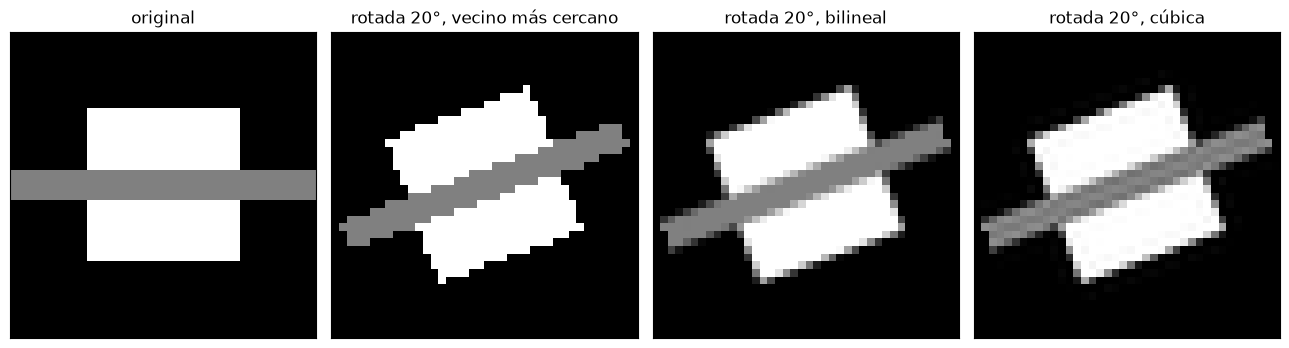

In [3]:
img = np.zeros((40, 40))
img[10:30, 10:30] = 1; img[18:22, :] = 0.5
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
axs[0].imshow(img, cmap='gray', vmin=0, vmax=1); axs[0].set_title('original')
for a, orden, nom in zip(axs[1:], [0, 1, 3], ['vecino más cercano', 'bilineal', 'cúbica']):
    a.imshow(ndimage.rotate(img, 20, order=orden, reshape=False), cmap='gray', vmin=0, vmax=1)
    a.set_title(f'rotada 20°, {nom}')
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Correcciones radiométricas: errores del sensor

Algunos defectos de la imagen vienen del sensor. El bandeado (striping) aparece cuando los detectores que registran líneas o columnas distintas no están perfectamente calibrados entre sí, y produce franjas periódicas; se corrige igualando la media y la desviación estándar de cada detector con las de toda la imagen. La pérdida de líneas (line drop) ocurre cuando un detector falla y deja líneas sin datos, que se rellenan con el promedio de las vecinas; el caso más conocido es el fallo del corrector de líneas de Landsat 7 en 2003, que dejó franjas sin datos en todas sus imágenes posteriores. El ruido aleatorio de bits produce píxeles aislados muy brillantes u oscuros, el efecto sal y pimienta, que se elimina con un filtro de mediana. La celda siguiente simula y corrige los tres defectos.

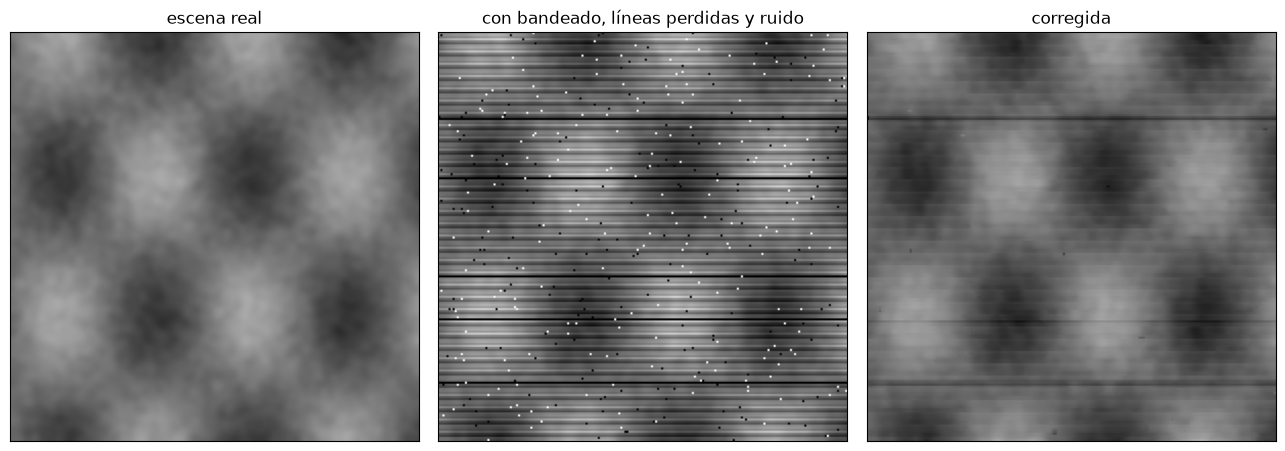

Error medio absoluto respecto a la escena real: defectuosa 0.060, corregida 0.026


In [4]:
n = 200
yy, xx = np.mgrid[0:n, 0:n]
limpia = 0.3 + 0.15 * np.sin(xx / 15) * np.cos(yy / 22) + ndimage.gaussian_filter(rng.normal(0, 0.08, (n, n)), 2)
# bandeado: 6 detectores con ganancia y desplazamiento distintos
ganancia = 1 + rng.normal(0, 0.08, 6); despl = rng.normal(0, 0.03, 6)
det = yy % 6
bandeada = limpia * ganancia[det] + despl[det]
# pérdida de líneas y ruido sal y pimienta
defectuosa = bandeada.copy()
defectuosa[rng.choice(n, 5, replace=False)] = 0
mascara_sp = rng.random((n, n)) < 0.01
defectuosa[mascara_sp] = rng.choice([0.0, 1.0], mascara_sp.sum())

corr = defectuosa.copy()
corr = ndimage.median_filter(corr, size=3)                         # sal y pimienta y líneas aisladas
for d in range(6):                                                  # destriping por igualación de momentos
    filas = corr[d::6]
    corr[d::6] = (filas - filas.mean()) / filas.std() * corr.std() + corr.mean()
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
for a, im, t in zip(axs, [limpia, defectuosa, corr], ['escena real', 'con bandeado, líneas perdidas y ruido', 'corregida']):
    a.imshow(im, cmap='gray', vmin=0, vmax=0.7); a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f'Error medio absoluto respecto a la escena real: defectuosa {np.abs(defectuosa-limpia).mean():.3f}, corregida {np.abs(corr-limpia).mean():.3f}')

## De nivel digital a reflectancia en el tope de la atmósfera

El nivel digital es un número sin unidades. Para convertirlo en radiancia espectral en el sensor se usan los coeficientes de calibración que vienen en los metadatos de cada escena, una ganancia y un desplazamiento por banda: $L = G \cdot ND + B$. La radiancia depende todavía de la iluminación, que cambia con la fecha y la hora, de modo que para comparar imágenes se convierte en reflectancia en el tope de la atmósfera, corrigiendo la irradiancia solar exoatmosférica de la banda ($E_{sol}$), la distancia Tierra-Sol en unidades astronómicas ($d$) y el ángulo cenital solar ($\theta_s$):

$$\rho_{TOA} = \frac{\pi\, L\, d^2}{E_{sol}\, \cos\theta_s}.$$

Esta es la corrección solar. Los productos Landsat de nivel 1 ya traen coeficientes que convierten el ND directamente en reflectancia TOA, y Sentinel-2 L1C entrega directamente reflectancia TOA escalada por 10 000.

In [5]:
def dist_tierra_sol(dia):
    return 1 - 0.01672 * np.cos(np.radians(0.9856 * (dia - 4)))

ND = np.array([8500, 9200, 7600, 21000])                  # rojo y NIR de dos coberturas, 16 bits
G, Boff, E_sol = 0.0118, -59.0, 1554.0                     # valores típicos para la banda roja de OLI
for dia, elev in [(15, 52), (196, 68)]:
    L = G * ND + Boff
    d = dist_tierra_sol(dia)
    rho = np.pi * L * d**2 / (E_sol * np.cos(np.radians(90 - elev)))
    print(f'día {dia:3d}, elevación solar {elev}°, d = {d:.4f} UA -> radiancia {np.round(L,1)}  reflectancia TOA {np.round(rho,3)}')

día  15, elevación solar 52°, d = 0.9836 UA -> radiancia [ 41.3  49.6  30.7 188.8]  reflectancia TOA [0.103 0.123 0.076 0.469]
día 196, elevación solar 68°, d = 1.0165 UA -> radiancia [ 41.3  49.6  30.7 188.8]  reflectancia TOA [0.093 0.112 0.069 0.425]


El mismo nivel digital da reflectancias distintas en enero y en julio porque la iluminación es distinta. Sin esta corrección, una comparación entre las dos fechas confundiría el cambio de iluminación con un cambio en la superficie.

## Corrección atmosférica

La reflectancia TOA todavía incluye la contribución de la atmósfera: la radiancia de trayectoria, la luz dispersada hacia el sensor sin llegar a la superficie, que aclara la imagen sobre todo en el azul, y la atenuación de la señal en sus dos recorridos. La corrección atmosférica estima la reflectancia de superficie. Los métodos rigurosos usan modelos de transferencia radiativa, como 6S o MODTRAN, con datos de aerosoles y vapor de agua, y son los que aplican las agencias para generar los productos de nivel 2 (LaSRC en Landsat y Sen2Cor en Sentinel-2). Un método empírico sencillo es la sustracción del objeto oscuro (DOS) {cite}`chavez1988`: supone que en cada banda hay píxeles que deberían tener reflectancia casi nula, como el agua profunda o las sombras, y que su valor observado se debe solo a la radiancia de trayectoria, que se resta a toda la banda. La celda siguiente aplica la idea a una escena simulada.

In [6]:
bandas = ['azul', 'verde', 'rojo', 'NIR']
rho_sup = {'agua': [0.04, 0.05, 0.03, 0.01], 'vegetación': [0.03, 0.08, 0.04, 0.42], 'suelo': [0.10, 0.15, 0.20, 0.28]}
trayectoria = np.array([0.09, 0.055, 0.03, 0.01])          # radiancia de trayectoria (en reflectancia), mayor en el azul
transm = np.array([0.80, 0.85, 0.88, 0.92])
print(f'{"cobertura":11s} {"banda":6s} {"superficie":>10s} {"TOA":>7s} {"DOS":>7s}')
oscuro = transm * np.array(rho_sup['agua']) * transm + trayectoria    # píxel oscuro de la escena
oscuro_min = np.min([transm * np.array(v) * transm + trayectoria for v in rho_sup.values()], axis=0)
for cob, v in rho_sup.items():
    toa = transm * np.array(v) * transm + trayectoria
    dos = toa - oscuro_min + 0.01                          # se deja un 1 % como reflectancia mínima esperada
    for b, s, t_, d_ in zip(bandas, v, toa, dos):
        print(f'{cob:11s} {b:6s} {s:10.3f} {t_:7.3f} {d_:7.3f}')

cobertura   banda  superficie     TOA     DOS
agua        azul        0.040   0.116   0.016
agua        verde       0.050   0.091   0.010
agua        rojo        0.030   0.053   0.010
agua        NIR         0.010   0.018   0.010
vegetación  azul        0.030   0.109   0.010
vegetación  verde       0.080   0.113   0.032
vegetación  rojo        0.040   0.061   0.018
vegetación  NIR         0.420   0.365   0.357
suelo       azul        0.100   0.154   0.055
suelo       verde       0.150   0.163   0.082
suelo       rojo        0.200   0.185   0.142
suelo       NIR         0.280   0.247   0.239


El DOS elimina la mayor parte del aclaramiento en el azul, pero no la atenuación, de modo que las reflectancias altas quedan algo subestimadas. Por eso, siempre que existan, conviene usar los productos de nivel 2 de las agencias.

## Corrección topográfica

En zonas montañosas, una misma cobertura se ve más brillante en las laderas que miran hacia el Sol y más oscura en las opuestas. La corrección topográfica tiene en cuenta la iluminación local, el coseno del ángulo de incidencia $i$ entre el Sol y la normal al terreno, calculado con un modelo de elevación. La corrección del coseno, $\rho_h = \rho\,\cos\theta_s / \cos i$, sobrecorrige las laderas poco iluminadas; la corrección C, $\rho_h = \rho\,(\cos\theta_s + C)/(\cos i + C)$, con $C$ estimada por regresión entre $\rho$ y $\cos i$, es más robusta y es la más usada. La celda siguiente la aplica a un cerro sintético cubierto por un bosque homogéneo.

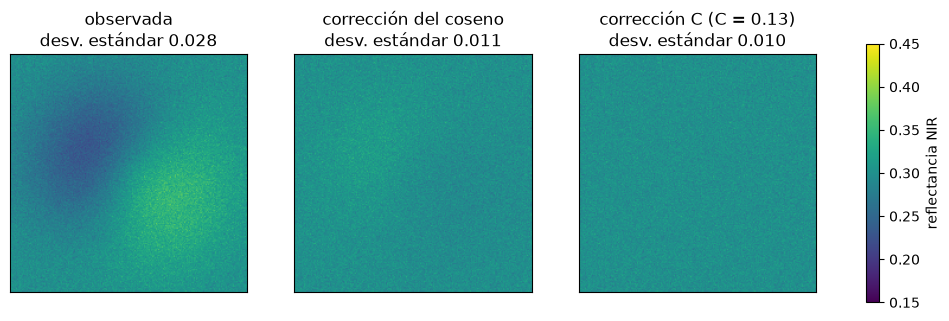

In [7]:
n = 200
yy, xx = np.mgrid[0:n, 0:n] * 30.0
dem = 1500 + 600 * np.exp(-((xx - 3000)**2 + (yy - 3000)**2) / 2 * 1 / 1300**2)
gy, gx = np.gradient(dem, 30)
pend = np.arctan(np.hypot(gx, gy)); asp = np.arctan2(-gx, gy)
theta_s, az_s = np.radians(40), np.radians(120)
cos_i = np.cos(theta_s) * np.cos(pend) + np.sin(theta_s) * np.sin(pend) * np.cos(az_s - asp)
rho_real = 0.30 + rng.normal(0, 0.01, dem.shape)
rho_obs = rho_real * cos_i / np.cos(theta_s) * 0.85 + 0.15 * rho_real        # parte difusa no depende de la pendiente
m, b = np.polyfit(cos_i.ravel(), rho_obs.ravel(), 1); C = b / m
rho_cos = rho_obs * np.cos(theta_s) / np.clip(cos_i, 0.05, None)
rho_c = rho_obs * (np.cos(theta_s) + C) / (cos_i + C)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for a, im, t in zip(axs, [rho_obs, rho_cos, rho_c], ['observada', 'corrección del coseno', f'corrección C (C = {C:.2f})']):
    h = a.imshow(im, cmap='viridis', vmin=0.15, vmax=0.45); a.set_title(f'{t}\ndesv. estándar {im.std():.3f}')
    a.set_xticks([]); a.set_yticks([])
fig.colorbar(h, ax=axs, shrink=0.8, label='reflectancia NIR')
plt.show()

## Para profundizar

El capítulo 6 de {cite}`chuvieco2008` y los capítulos 2 a 4 de {cite}`richards2013` tratan las correcciones geométricas y radiométricas en detalle. {cite:t}`schowengerdt2007` desarrolla los modelos de sensor y de remuestreo. El taller de descarga del curso muestra cómo obtener directamente productos de nivel 2 de Landsat y Sentinel-2.